In [15]:
import kagglehub
from datasets import load_dataset
import pandas as pd
import dataframes as df
import matplotlib.pyplot as plt
import kagglehub
# Download latest version
path = kagglehub.dataset_download("ealtman2019/ibm-transactions-for-anti-money-laundering-aml")

print("Path to dataset files:", path)

Path to dataset files: /Users/lachlanbruce/.cache/kagglehub/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/versions/8


In [17]:
import os
import pandas as pd

# Use the local path from kagglehub.dataset_download in the previous cell
DATA_DIR = path  # set by kagglehub above
print("Using DATA_DIR:", DATA_DIR)
print("Files:", os.listdir(DATA_DIR))

TRANS_FILE = os.path.join(DATA_DIR, "LI-Small_Trans.csv")
ACCOUNTS_FILE = os.path.join(DATA_DIR, "LI-Small_accounts.csv")
PATTERNS_FILE = os.path.join(DATA_DIR, "LI-Small_Patterns.txt")

df = pd.read_csv(TRANS_FILE)
df.head()
df.info()


Using DATA_DIR: /Users/lachlanbruce/.cache/kagglehub/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/versions/8
Files: ['LI-Small_Patterns.txt', 'LI-Medium_Patterns.txt', 'HI-Small_Patterns.txt', 'LI-Medium_Trans.csv', 'HI-Large_Patterns.txt', 'HI-Medium_Patterns.txt', 'HI-Medium_Trans.csv', 'LI-Large_Patterns.txt', 'LI-Medium_accounts.csv', 'HI-Small_Trans.csv', 'HI-Small_accounts.csv', 'LI-Small_accounts.csv', 'LI-Small_Trans.csv', 'HI-Medium_accounts.csv', 'LI-Large_Trans.csv', 'LI-Large_accounts.csv', 'HI-Large_Trans.csv', 'HI-Large_accounts.csv']
<class 'pandas.DataFrame'>
RangeIndex: 6924049 entries, 0 to 6924048
Data columns (total 11 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Timestamp           str    
 1   From Bank           int64  
 2   Account             str    
 3   To Bank             int64  
 4   Account.1           str    
 5   Amount Received     float64
 6   Receiving Currency  str    
 7   Amount Paid       

In [18]:
# From Bank / To Bank ID overlap
from_banks = set(df["From Bank"].unique())
to_banks = set(df["To Bank"].unique())
overlap = from_banks & to_banks

print(f"Unique From Bank: {len(from_banks):,}")
print(f"Unique To Bank:   {len(to_banks):,}")
print(f"Overlapping IDs:  {len(overlap):,}")
print(f"Overlap as % of From Bank: {100 * len(overlap) / len(from_banks):.4f}%")
print(f"Overlap as % of To Bank:   {100 * len(overlap) / len(to_banks):.4f}%")

if overlap:
    print("Example overlapping bank IDs:", list(overlap)[:10])
else:
    print("No overlap — From Bank and To Bank occupy disjoint ID spaces.")


Unique From Bank: 41,814
Unique To Bank:   21,588
Overlapping IDs:  21,587
Overlap as % of From Bank: 51.6262%
Overlap as % of To Bank:   99.9954%
Example overlapping bank IDs: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(10), np.int64(11)]


In [ ]:

dataset = load_dataset('CiferAI/Cifer-Fraud-Detection-Dataset-AF', split='train')
df_cifer = dataset.to_pandas()

/Users/lachlanbruce/Documents/QDetect_CODE/Q-Detect/MachineLearning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
path = kagglehub.dataset_download("ealtman2019/credit-card-transactions")
df_ibm = pd.read_csv(f"{path}/credit_card_transactions-ibm_v2.csv")

In [4]:
path = kagglehub.dataset_download("ealaxi/paysim1")
df_paysim = pd.read_csv(f"{path}/PS_20174392719_1491204439457_log.csv")

Numb of rows

In [ ]:
print(df_cifer.shape)
print(df_ibm.shape)
print(df_paysim.shape)

(21000000, 11)
(24386900, 15)
(6362620, 11)


unique values

In [5]:
df_cifer.info()
df_ibm.info()
df_paysim.info()

<class 'pandas.DataFrame'>
RangeIndex: 21000000 entries, 0 to 20999999
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 2.3 GB
<class 'pandas.DataFrame'>
RangeIndex: 24386900 entries, 0 to 24386899
Data columns (total 15 columns):
 #   Column          Dtype  
---  ------          -----  
 0   User            int64  
 1   Card            int64  
 2   Year            int64  
 3   Month           int64  
 4   Day             int64  
 5   Time            str    
 6   Amount          str    
 7   Use Chip        str    
 8   Merchant Name   int64  
 9   Merchant City   str    
 10  Merc

In [6]:
print("--------------------------------")
print("Unique values of each column cifer")
print("--------------------------------")
unique_counts = df_cifer.nunique(dropna=True)

print(unique_counts)

print("--------------------------------")
print("Unique values of each column ibm")
print("--------------------------------")
unique_counts = df_ibm.nunique(dropna=True)

print(unique_counts)

print("--------------------------------")
print("Unique values of each column paysim")
print("--------------------------------")
unique_counts = df_paysim.nunique(dropna=True)

print(unique_counts)

--------------------------------
Unique values of each column cifer
--------------------------------
step                   743
type                     5
amount            14547645
nameOrig          11464100
oldbalanceOrg     15636160
newbalanceOrig    17878751
nameDest           8219031
oldbalanceDest    20014124
newbalanceDest    12795992
isFraud                  2
isFlaggedFraud           2
dtype: int64
--------------------------------
Unique values of each column ibm
--------------------------------
User                2000
Card                   9
Year                  30
Month                 12
Day                   31
Time                1440
Amount             98953
Use Chip               3
Merchant Name     100343
Merchant City      13429
Merchant State       223
Zip                27321
MCC                  109
Errors?               23
Is Fraud?              2
dtype: int64
--------------------------------
Unique values of each column paysim
--------------------------------


Occurence of fraud

In [4]:
# Check for occurence of fraud
print("--------------------------------")
print("Occurence of fraud")
print("-------------------------")
print(df_cifer['isFraud'].value_counts())
print(df_cifer['isFraud'].value_counts(normalize=True) * 100)

# Check for occurence of fraud
print("--------------------------------")
print("Occurence of fraud")
print("-------------------------")
print(df_ibm['Is Fraud?'].value_counts())
print(df_ibm['Is Fraud?'].value_counts(normalize=True) * 100)


# Check for occurence of fraud
print("--------------------------------")
print("Occurence of fraud")
print("-------------------------")
print(df_paysim['isFraud'].value_counts())
print(df_paysim['isFraud'].value_counts(normalize=True) * 100)

--------------------------------
Occurence of fraud
-------------------------
isFraud
0    20972530
1       27470
Name: count, dtype: int64
isFraud
0    99.86919
1     0.13081
Name: proportion, dtype: float64
--------------------------------
Occurence of fraud
-------------------------
Is Fraud?
No     24357143
Yes       29757
Name: count, dtype: int64
Is Fraud?
No     99.87798
Yes     0.12202
Name: proportion, dtype: float64
--------------------------------
Occurence of fraud
-------------------------
isFraud
0    6354407
1       8213
Name: count, dtype: int64
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


Average number of transactions per user and per merchant


In [7]:
# Average / max / min transactions per user and per merchant
for name, frame, user_col, merchant_col in [
    ("Cifer", df_cifer, "nameOrig", "nameDest"),
    ("IBM", df_ibm, "User", "Merchant Name"),
    ("PaySim", df_paysim, "nameOrig", "nameDest"),
]:
    print("--------------------------------")
    print(f"{name}")
    print("-------------------------")
    for entity, col in [("user", user_col), ("merchant", merchant_col)]:
        tx_per = frame[col].value_counts()
        most = tx_per.idxmax()
        least = tx_per.idxmin()
        print(f"Transactions per {entity} ({col})")
        print(f"  Average: {tx_per.mean():.2f}")
        print(f"  Max:     {tx_per.max()}  ({entity}: {most})")
        print(f"  Min:     {tx_per.min()}  ({entity}: {least})")
    print()


--------------------------------
Cifer
-------------------------
Transactions per user (nameOrig)
  Average: 1.83
  Max:     14  (user: C2043257944)
  Min:     1  (user: sdv-pii-r8zd6)
Transactions per merchant (nameDest)
  Average: 2.56
  Max:     292  (merchant: C985934102)
  Min:     1  (merchant: sdv-pii-q6998)

--------------------------------
IBM
-------------------------
Transactions per user (User)
  Average: 12193.45
  Max:     82355  (user: 486)
  Min:     15  (user: 1817)
Transactions per merchant (Merchant Name)
  Average: 243.04
  Max:     1130230  (merchant: 1799189980464955940)
  Min:     1  (merchant: 8770419670485183201)

--------------------------------
PaySim
-------------------------
Transactions per user (nameOrig)
  Average: 1.00
  Max:     3  (user: C2098525306)
  Min:     1  (user: C1231006815)
Transactions per merchant (nameDest)
  Average: 2.34
  Max:     113  (merchant: C1286084959)
  Min:     1  (merchant: M1979787155)



Do user and merchant IDs overlap? (IBM + Cifer)


In [9]:
# User / merchant ID overlap — same ID appearing as both roles
for name, frame, user_col, merchant_col in [
    ("IBM", df_ibm, "User", "Merchant Name"),
    ("Cifer", df_cifer, "nameOrig", "nameDest"),
]:
    users = set(frame[user_col].unique())
    merchants = set(frame[merchant_col].unique())
    overlap = users & merchants

    print("--------------------------------")
    print(f"{name} — {user_col} ∩ {merchant_col}")
    print("-------------------------")
    print(f"Unique users:     {len(users):,}")
    print(f"Unique merchants: {len(merchants):,}")
    print(f"Overlapping IDs:  {len(overlap):,}")
    print(f"Overlap as % of users:     {100 * len(overlap) / len(users):.4f}%")
    print(f"Overlap as % of merchants: {100 * len(overlap) / len(merchants):.4f}%")
    if overlap:
        print("Example overlapping IDs:", list(overlap)[:10])
    else:
        print("No overlap — user and merchant occupy disjoint ID spaces.")
    print()


--------------------------------
IBM — User ∩ Merchant Name
-------------------------
Unique users:     2,000
Unique merchants: 100,343
Overlapping IDs:  0
Overlap as % of users:     0.0000%
Overlap as % of merchants: 0.0000%
No overlap — user and merchant occupy disjoint ID spaces.

--------------------------------
Cifer — nameOrig ∩ nameDest
-------------------------
Unique users:     11,464,100
Unique merchants: 8,219,031
Overlapping IDs:  540,135
Overlap as % of users:     4.7115%
Overlap as % of merchants: 6.5718%
Example overlapping IDs: ['sdv-pii-65lku', 'sdv-pii-0k6t5', 'sdv-pii-58fqs', 'sdv-pii-gjujg', 'sdv-pii-un04e', 'sdv-pii-sc8h6', 'sdv-pii-2vgkz', 'sdv-pii-v1ca5', 'sdv-pii-0mfyg', 'sdv-pii-sm8b4']



Graph connectivity


In [1]:
# Degree / one-shot / shared destinations
# Cifer & PaySim: nameOrig -> nameDest | IBM: User -> Merchant Name
for name, frame, src_col, dst_col in [
    ("Cifer", df_cifer, "nameOrig", "nameDest"),
    ("IBM", df_ibm, "User", "Merchant Name"),
    ("PaySim", df_paysim, "nameOrig", "nameDest"),
]:
    out_deg = frame[src_col].value_counts()
    in_deg = frame[dst_col].value_counts()
    n_src = frame[src_col].nunique()
    n_dst = frame[dst_col].nunique()
    n_nodes = pd.concat([frame[src_col], frame[dst_col]]).nunique()
    senders_per_dst = frame.groupby(dst_col)[src_col].nunique()

    print("--------------------------------")
    print(f"{name} — connectivity ({src_col} → {dst_col})")
    print("-------------------------")
    print(f"Unique sources:      {n_src:,}")
    print(f"Unique destinations: {n_dst:,}")
    print(f"Unique nodes total:  {n_nodes:,}")
    print(f"Edges (rows):        {len(frame):,}")
    print(f"Out-degree mean/max: {out_deg.mean():.2f} / {out_deg.max()}")
    print(f"In-degree mean/max:  {in_deg.mean():.2f} / {in_deg.max()}")
    print(f"% sources with 1 tx: {(out_deg == 1).mean() * 100:.2f}%")
    print(f"Senders per dest — mean/max: {senders_per_dst.mean():.2f} / {senders_per_dst.max()}")


NameError: name 'df_cifer' is not defined

Connected components (100k sample)


In [13]:
# Connected components on a sample (full graphs are too large)
import networkx as nx

SAMPLE_SIZE = 100_000
RNG = 42

for name, frame, src_col, dst_col in [
    ("Cifer", df_cifer, "nameOrig", "nameDest"),
    ("IBM", df_ibm, "User", "Merchant Name"),
    ("PaySim", df_paysim, "nameOrig", "nameDest"),
]:
    sample = frame.sample(n=min(SAMPLE_SIZE, len(frame)), random_state=RNG)
    G = nx.from_pandas_edgelist(sample, src_col, dst_col)
    n_comp = nx.number_connected_components(G)
    largest = len(max(nx.connected_components(G), key=len))
    largest_frac = largest / G.number_of_nodes()

    print("--------------------------------")
    print(f"{name} — connected components (sample={len(sample):,})")
    print("-------------------------")
    print(f"Nodes:                 {G.number_of_nodes():,}")
    print(f"Edges:                 {G.number_of_edges():,}")
    print(f"Connected components:  {n_comp:,}")
    print(f"Largest component:     {largest:,} ({largest_frac * 100:.2f}% of nodes)")


--------------------------------
Cifer — connected components (sample=100,000)
-------------------------
Nodes:                 195,364
Edges:                 100,000
Connected components:  95,364
Largest component:     7 (0.00% of nodes)
--------------------------------
IBM — connected components (sample=100,000)
-------------------------
Nodes:                 13,149
Edges:                 40,220
Connected components:  26
Largest component:     13,094 (99.58% of nodes)
--------------------------------
PaySim — connected components (sample=100,000)
-------------------------
Nodes:                 192,912
Edges:                 100,000
Connected components:  92,912
Largest component:     7 (0.00% of nodes)


Transaction time frame (step skew)

PaySim and Cifer both use `step` as the time unit (1 step = 1 hour, ~30-day simulation). The plots below show where transaction volume concentrates across steps — a right/left skew means most activity sits early or late in the simulation.

IBM minimum date — month: 1, year: 1991
IBM maximum date — month: 2, year: 2020
--------------------------------
Cifer — step time frame
-------------------------
Min / max step:     1 / 743
Unique steps:       743
Mean / median:      238.87 / 205.00
Skewness:           0.913
Busiest step:       743 (210,032 txs)
Quietest step:      742 (2,114 txs)
--------------------------------
PaySim — step time frame
-------------------------
Min / max step:     1 / 743
Unique steps:       743
Mean / median:      243.40 / 239.00
Skewness:           0.375
Busiest step:       19 (51,352 txs)
Quietest step:      112 (2 txs)


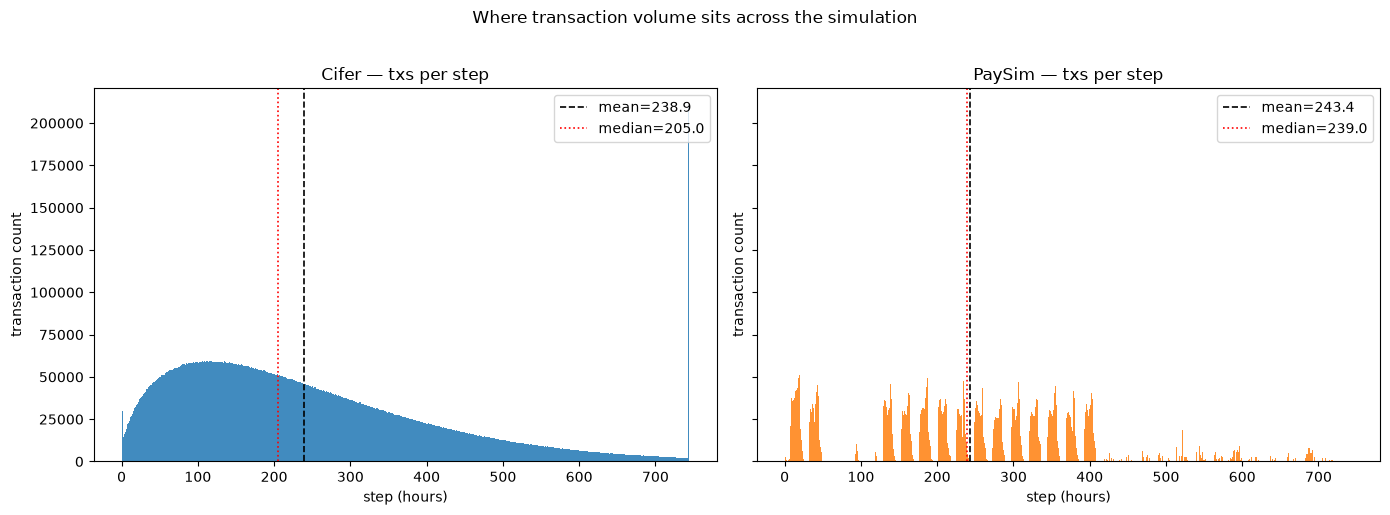

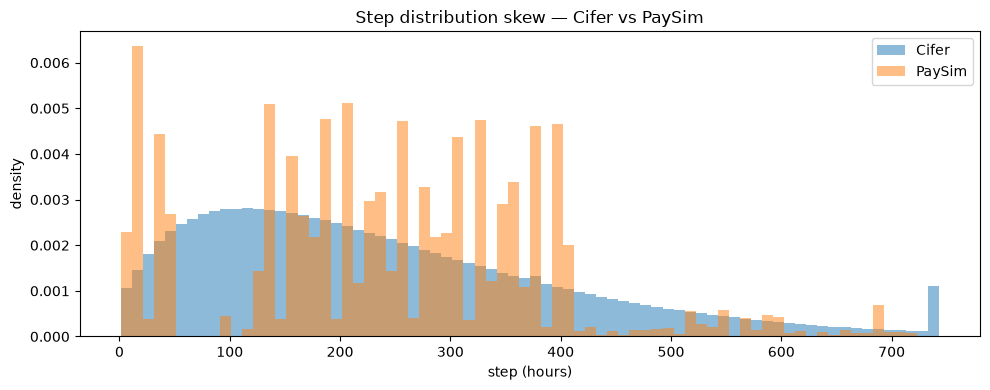

In [17]:


# IBM earliest / latest date (month paired with that year)
dates = df_ibm[["Year", "Month"]].sort_values(["Year", "Month"])
min_year, min_month = int(dates.iloc[0]["Year"]), int(dates.iloc[0]["Month"])
max_year, max_month = int(dates.iloc[-1]["Year"]), int(dates.iloc[-1]["Month"])
print(f"IBM minimum date — month: {min_month}, year: {min_year}")
print(f"IBM maximum date — month: {max_month}, year: {max_year}")

# Compare step distributions (where transaction volume concentrates)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, name, frame, color in [
    (axes[0], "Cifer", df_cifer, "#1f77b4"),
    (axes[1], "PaySim", df_paysim, "#ff7f0e"),
]:
    steps = frame["step"]
    counts = steps.value_counts().sort_index()

    ax.bar(counts.index, counts.values, width=1.0, color=color, alpha=0.85)
    ax.axvline(steps.mean(), color="black", linestyle="--", linewidth=1.2, label=f"mean={steps.mean():.1f}")
    ax.axvline(steps.median(), color="red", linestyle=":", linewidth=1.2, label=f"median={steps.median():.1f}")
    ax.set_title(f"{name} — txs per step")
    ax.set_xlabel("step (hours)")
    ax.set_ylabel("transaction count")
    ax.legend(loc="upper right")

    print("--------------------------------")
    print(f"{name} — step time frame")
    print("-------------------------")
    print(f"Min / max step:     {steps.min()} / {steps.max()}")
    print(f"Unique steps:       {steps.nunique()}")
    print(f"Mean / median:      {steps.mean():.2f} / {steps.median():.2f}")
    print(f"Skewness:           {steps.skew():.3f}")
    print(f"Busiest step:       {counts.idxmax()} ({counts.max():,} txs)")
    print(f"Quietest step:      {counts.idxmin()} ({counts.min():,} txs)")

plt.suptitle("Where transaction volume sits across the simulation", y=1.02)
plt.tight_layout()
plt.show()

# Overlay density (same scale) to compare skew shape directly
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df_cifer["step"], bins=74, density=True, alpha=0.5, label="Cifer", color="#1f77b4")
ax.hist(df_paysim["step"], bins=74, density=True, alpha=0.5, label="PaySim", color="#ff7f0e")
ax.set_xlabel("step (hours)")
ax.set_ylabel("density")
ax.set_title("Step distribution skew — Cifer vs PaySim")
ax.legend()
plt.tight_layout()
plt.show()